# Detecção e diagnóstico de falhas em rolamentos — CWRU 48 kHz

**ECM514 — Ciência de Dados · Projeto Desafio do 2º semestre de 2026**

**Integrantes:** Nome Sobrenome (RA) · Nome Sobrenome (RA) · Nome Sobrenome (RA)

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rodrigo-faltz/CD2026-S2/blob/main/CWRU_Projeto.ipynb)
· [Repositório](https://github.com/rodrigo-faltz/CD2026-S2) · [Relatório técnico](https://github.com/rodrigo-faltz/CD2026-S2/blob/main/RELATORIO.md)

Este notebook é a implementação completa do projeto. Ele baixa os dados reais do *Bearing Data Center* da Case Western
Reserve University, confere a integridade de cada arquivo, extrai atributos, treina e avalia os modelos e gera todas as
figuras e tabelas usadas no relatório.

**Perguntas que o trabalho responde**

1. **Detecção:** um modelo treinado só com vibração *normal* consegue alarmar quando surge um defeito, sem alarmes falsos?
2. **Diagnóstico:** é possível dizer *onde* está o defeito — pista interna, esfera ou pista externa?
3. **Generalização:** os modelos continuam funcionando numa **carga** de motor que não viram no treino? E num
   **tamanho de defeito** que não viram?

**Como executar:** *Ambiente de execução → Executar tudo*. Não precisa de GPU, conta do Kaggle nem upload de arquivos.
A execução leva cerca de 3 a 5 minutos, incluindo o download de ~275 MB.

## 1. Configuração

Parâmetros fixados antes de qualquer avaliação:

- **Taxa de amostragem de 48 kHz.** Normais e falhas vêm da mesma taxa de aquisição — não há reamostragem.
- **Janelas de 16.384 amostras** (0,34 s, cerca de 10 rotações do eixo), sem sobreposição. A janela precisa ser longa o
  bastante para resolver as frequências de defeito no espectro de envelope (resolução de 2,9 Hz).
- **Semente 42** em todos os modelos com aleatoriedade.

In [1]:
import hashlib
import importlib.metadata
import json
import platform
import sys
import time
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Markdown, display
from scipy.io import loadmat
from scipy.signal import butter, hilbert, sosfiltfilt, welch
from scipy.stats import kurtosis, skew
from sklearn.covariance import LedoitWolf
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix,
                             f1_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings('ignore', category=UserWarning)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

ROOT = Path.cwd()
RAW = ROOT / 'dados' / 'raw'
OUT = ROOT / 'resultados'
RAW.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

SEED = 42
FS = 48_000      # Hz — normal e falhas vêm da mesma taxa de aquisição
WINDOW = 16_384  # amostras por janela = 0,341 s ≈ 10 rotações do eixo
CLASSES = ['Normal', 'Pista interna', 'Esfera', 'Pista externa']
SHORT = {'Normal': 'N', 'Pista interna': 'PI', 'Esfera': 'E', 'Pista externa': 'PE'}

## 2. Dados

### 2.1 Origem e bancada

A bancada do CWRU tem um motor Reliance Electric de 2 HP, um transdutor de torque/encoder e um dinamômetro. Defeitos
pontuais foram usinados por eletroerosão (EDM) em rolamentos SKF 6205-2RS JEM no lado do acionamento (*drive end*, DE).
A vibração foi medida por acelerômetros com base magnética na carcaça. São **dados reais medidos em bancada**: os defeitos
são induzidos, mas nenhum sinal foi gerado por software.

### 2.2 Recorte e por que ele foi escolhido

| Item | Escolha | Motivo |
|---|---|---|
| Taxa | Coleção de **48 kHz** do drive end | É a mesma taxa dos arquivos normais (97–100). Usar a coleção de 12 kHz exigiria reamostrar o normal, e a diferença de aquisição poderia ser aprendida no lugar da falha. |
| Classes | Normal, pista interna, esfera, pista externa | São os três tipos de defeito do dataset mais a condição sem defeito. |
| Diâmetros | 0,007", 0,014" e 0,021" | São os diâmetros disponíveis a 48 kHz (0,028" só existe a 12 kHz e sem pista externa). |
| Pista externa | Somente posição **6h** | As posições 3h e 12h não existem para 0,014". Incluí-las desequilibraria a classe e misturaria posição com severidade. |
| Cargas | 0, 1, 2 e 3 HP | Todas — usadas como grupos de validação cruzada. |
| Canal | Somente `*_DE_time` | É o sensor junto do rolamento defeituoso. |

São **40 gravações**: 4 normais e 36 com falha (3 tipos × 3 diâmetros × 4 cargas).

In [2]:
# Tabelas oficiais: "Normal Baseline Data" e "48k Drive End Bearing Fault Data".
FAULT_FILES = {
    #  (classe, diâmetro em polegadas): arquivos para cargas 0, 1, 2 e 3 HP
    ('Pista interna', 0.007): [109, 110, 111, 112],
    ('Pista interna', 0.014): [174, 175, 176, 177],
    ('Pista interna', 0.021): [213, 214, 215, 217],
    ('Esfera', 0.007): [122, 123, 124, 125],
    ('Esfera', 0.014): [189, 190, 191, 192],
    ('Esfera', 0.021): [226, 227, 228, 229],
    ('Pista externa', 0.007): [135, 136, 137, 138],   # posição 6h
    ('Pista externa', 0.014): [201, 202, 203, 204],
    ('Pista externa', 0.021): [238, 239, 240, 241],
}
NORMAL_FILES = [97, 98, 99, 100]
NOMINAL_RPM = {0: 1797, 1: 1772, 2: 1750, 3: 1730}

# Exceções documentadas da fonte: o arquivo 174 contém a variável X173 (gravação curta),
# e os arquivos 99, 175 e 217 contêm variáveis de outras gravações além da própria.
CHANNEL_OVERRIDE = {174: 'X173_DE_time'}
RPM_OVERRIDE = {174: 'X173RPM'}

EXPECTED_SHA256 = {
    97: '16bf48babcf1c7ac224bc1a81cd9eafdb27e42d5cf559761907e067e8eeadf3c',
    98: '37e6612c05e65c415dcfa2ab27a3fda648a5863160fa898b884a14743044e045',
    99: '4b97e6b5361f45efb6951dc3b1aebcdb3b89cb69d0f96d6f5c297dd9f45eee75',
    100: '88a5990cb541320e91505a1d72139e1993500ffe6e292a451011667f4138ca78',
    109: 'daddef5f784879becdf8fefbe2453f11c3cfc8d061a2a671da2f546d1bb48460',
    110: '9e2bc579af6f4e6d9d26bf63b7ed84ecba7775740d56a3737cc8f04f73c22d1a',
    111: 'a2e64a397a990efb91ba55252a84796f755bda3eb097c4b47cc0730a08dab309',
    112: '1775db11999f268c6ccf04b3ee19857f90a3636f4a582f1abd9a627f991e72d4',
    122: 'f392129bf3b43360b964d4e5b3479d0797d1647af8359934b0f56b9abab4739a',
    123: 'a1932ec4bad2460238088ca523fdcec6498e562e91f86255863d3987d9fcd558',
    124: '88719243f1b7dbe795c108acaf67ca0115c51517ac35a3fe3460eb07917b2a9a',
    125: '2607d0c291ed9a6138aed3eed7015e133f1cf866ac5cdf2251921f08d058f362',
    135: '5a1c3ceec1f2b58af9e01051e425aa9d31dd018f58a8d31cda25bbdb1ac6dca9',
    136: '37f259eebbc92afa8bd1b445d02af14e83608a48cd7a3cf5c323515ddc2d0f24',
    137: 'a81b621153e426aa32848be8157c42bcd81065a28ac7655a9a6597f3889fa3ef',
    138: 'b43eeb67badeb129047ddd3658bf673815dc4bd445facb4217eb04653bb2e11d',
    174: 'ca7113a900d9217aa5632e0dad4f8791caed4d314321daa011719e1bc99f3026',
    175: '18302e96425ad163db699da3a2ca63d8f6ef4dfc99172e97ab21a8a77a83ac17',
    176: '569c7b292018e7e88cf4b375b091433c7566b9503545188979e93f6428427247',
    177: '5cffc5aa2b1e5cc65a97ebcfaa369b886ad8db8b8840e0e0095e97b8b9be4c16',
    189: '6fd84310f781e1ab54a9a746b8626c73a863f2b02cea4c86229ca2444cb20a9a',
    190: 'ae5fb00ce1eeefa5e21013197b186c0496f52820bdff00b385c58dfcb64a5b2f',
    191: 'bb39df077745821a3917e432ab1bc2f5d7c4e01a6e2338d1271b6994ec68dc7f',
    192: '099b7f3399d0ea81aedfab20667a9517059441c10f2a9d52130687cc9643e2c7',
    201: '6c27615a61f19f05f65cf2cc2aa4bca5bda051c9d93a708d0ee8baf5138834fa',
    202: '16f1a7eadbd6703a7a1ab1a32f8d7b97b6b85c1b31b1e760c123a9e175d8ae63',
    203: '3cad2848f4c96cde04fc06ca0f541ad663298ecb50eb7fc74e25b72ab29e1c5a',
    204: 'f3b1736698a580c2ea44cce78045833a9e76476d9153da8af5275c2e30e38a10',
    213: '6afb81f36a9efcdd370a52166d71c13cb42278c7de22752c81d4b2a22fa133f0',
    214: 'a8fe29f358b7f9c140f38e0cd7fbafdd7441c44e30a5b704ecb9be64cbb841ed',
    215: '1e3d65088782a29aa70004896db4b9836499dd12edd3c58fb496f4befca6f746',
    217: 'fb5b067c04b4c8449cbdd4ac4e376d7eb0804b9203efcab513e42aaf2f6a2cf7',
    226: 'fc78f08085760f2e17bcf7efe486b3a278e108093cd184acf278daecad6765e4',
    227: 'c5c7aa64243ecd1428999aae4be29ba5d4de9235fee9731352c6cce7de604675',
    228: 'ea819eb0404f76ccdbe6074463469bda8fbbe04b7c0c75cf1443d2b5ac3484f6',
    229: '4fc20e3eeef375dc1a8ac577f04b4b0e0fa9e319ec51a61f7a02e756b0069499',
    238: '63209a4057f199beb42beedf5b4481987fdb3ac746c46777dd385d689bc481df',
    239: '4ba7dc55258359577a68f6de5c0ff6675776d2b2c30d691dd4d71640e34834af',
    240: 'c5d8b4db09880b660da88865fff0e81afef0f5ad68bdf0ad7b75c722ae3e7e1c',
    241: 'cb64eed96d401837c25df63598b7d1a00868368e1ed503a8dcef1e5226ec9caa',
}

rows = [dict(file_id=fid, classe='Normal', diametro_pol=0.0, carga_hp=load)
        for load, fid in enumerate(NORMAL_FILES)]
for (label, diameter), ids in FAULT_FILES.items():
    rows += [dict(file_id=fid, classe=label, diametro_pol=diameter, carga_hp=load)
             for load, fid in enumerate(ids)]
manifest = pd.DataFrame(rows)
assert len(manifest) == 40 and manifest.file_id.is_unique
manifest.groupby(['classe', 'diametro_pol']).file_id.apply(list).to_frame('arquivos (0–3 HP)')

arquivos (0–3 HP)
classe        diametro_pol                      
Esfera        0.007         [122, 123, 124, 125]
              0.014         [189, 190, 191, 192]
              0.021         [226, 227, 228, 229]
Normal        0.000            [97, 98, 99, 100]
Pista externa 0.007         [135, 136, 137, 138]
              0.014         [201, 202, 203, 204]
              0.021         [238, 239, 240, 241]
Pista interna 0.007         [109, 110, 111, 112]
              0.014         [174, 175, 176, 177]
              0.021         [213, 214, 215, 217]

### 2.3 Download e integridade

Cada arquivo é conferido pelo **SHA-256**. Se o arquivo local estiver ausente ou divergente, ele é baixado da fonte
oficial e, se ela falhar, da cópia no repositório do grupo — sempre com o mesmo hash. Se nenhuma fonte entregar o arquivo
correto, a execução para: **não há dados substitutos ou sintéticos**.

Três peculiaridades conhecidas da fonte são tratadas explicitamente:

- `174.mat` (pista interna 0,014", 0 HP) contém a variável `X173_DE_time`, com apenas 1,3 s de sinal.
- `99.mat` contém também as variáveis do arquivo 98; usa-se apenas `X099_DE_time`.
- `175.mat` e `217.mat` contêm variáveis de outras gravações; usa-se apenas a do próprio arquivo.

A duração confirma a taxa: os normais 98–100 têm cerca de 485 mil amostras (10 s a 48 kHz), o mesmo comprimento das
gravações de falha da coleção de 48 kHz. Nos arquivos de 0 HP, normais e falhas têm cerca de 5 s.

In [3]:
SOURCES = [
    'https://engineering.case.edu/sites/default/files/{}.mat',                        # fonte oficial
    'https://raw.githubusercontent.com/rodrigo-faltz/CD2026-S2/main/dados/raw/{}.mat',  # cópia do grupo
]


def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def ensure_file(file_id, attempts=5):
    """Garante o arquivo original com hash conferido. Nunca gera dados substitutos.
    O servidor do CWRU às vezes interrompe a transferência; por isso há várias tentativas."""
    dest = RAW / f'{file_id}.mat'
    if dest.exists() and sha256(dest) == EXPECTED_SHA256[file_id]:
        return 'local'
    for template in SOURCES:
        url = template.format(file_id)
        for attempt in range(attempts):
            try:
                response = requests.get(url, timeout=(15, 120), headers={'User-Agent': 'Mozilla/5.0'})
                response.raise_for_status()
                content = response.content
            except requests.RequestException:
                content = b''
            if hashlib.sha256(content).hexdigest() == EXPECTED_SHA256[file_id]:
                dest.write_bytes(content)
                return url
            time.sleep(2 ** attempt)   # espera crescente antes de tentar de novo
    raise RuntimeError(f'Não foi possível obter {file_id}.mat com o hash esperado.')


origins = {fid: ensure_file(fid) for fid in manifest.file_id}
print('Arquivos verificados por SHA-256:', len(origins))
print('Origem:', pd.Series(origins).map(lambda s: 'local' if s == 'local' else s.split('/')[2]).value_counts().to_dict())


def load_recording(file_id, load):
    data = loadmat(RAW / f'{file_id}.mat')
    channel = CHANNEL_OVERRIDE.get(file_id, f'X{file_id:03d}_DE_time')
    signal = data[channel].ravel().astype(float)
    rpm_key = RPM_OVERRIDE.get(file_id, f'X{file_id:03d}RPM')
    rpm = float(data[rpm_key].ravel()[0]) if rpm_key in data else float(NOMINAL_RPM[load])
    assert np.isfinite(signal).all() and len(signal) >= WINDOW
    return signal, channel, rpm, rpm_key in data


signals = {}
info = []
for row in manifest.itertuples():
    x, channel, rpm, rpm_measured = load_recording(row.file_id, row.carga_hp)
    signals[row.file_id] = x
    info.append(dict(file_id=row.file_id, canal=channel, n_amostras=len(x),
                     duracao_s=round(len(x) / FS, 2), rpm=rpm, rpm_medido=rpm_measured,
                     sha256=EXPECTED_SHA256[row.file_id]))
manifest = manifest.merge(pd.DataFrame(info), on='file_id')
manifest['url_oficial'] = manifest.file_id.map(SOURCES[0].format)
manifest.to_csv(ROOT / 'dados' / 'manifesto.csv', index=False)
manifest.groupby('classe')[['n_amostras', 'duracao_s']].sum().reindex(CLASSES)

Arquivos verificados por SHA-256: 40
Origem: {'local': 40}


,n_amostras,duracao_s
classe,,
Normal,1698547,35.39
Pista interna,4830126,100.65
Esfera,5121960,106.69
Pista externa,5122638,106.72


## 3. Análise exploratória

Um exemplo de cada classe (1 HP; falhas de 0,007"). À esquerda, 0,34 s de sinal; à direita, o espectro de potência
estimado pelo método de Welch.

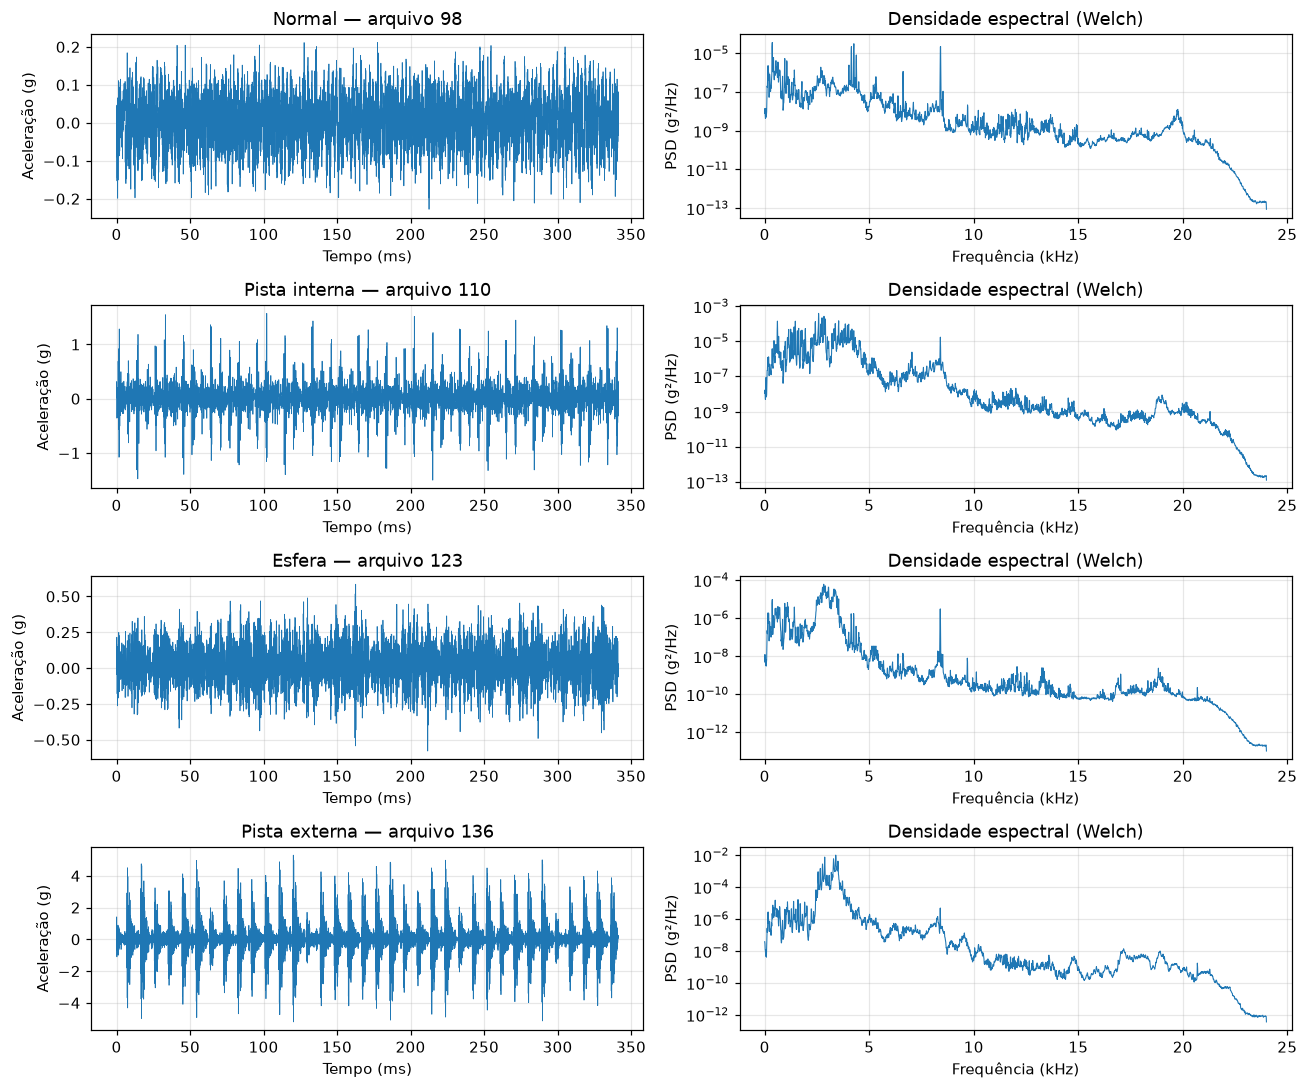

In [4]:
# Exemplos ilustrativos: carga de 1 HP e diâmetro de 0,007" (o normal não tem diâmetro).
example_ids = manifest[(manifest.carga_hp == 1) & (manifest.diametro_pol.isin([0.0, 0.007]))]
fig, axes = plt.subplots(4, 2, figsize=(12, 10))
for ax_row, label in zip(axes, CLASSES):
    fid = example_ids[example_ids.classe == label].file_id.iloc[0]
    x = signals[fid][:WINDOW]
    t = np.arange(len(x)) / FS * 1000
    ax_row[0].plot(t, x, lw=0.5)
    ax_row[0].set(title=f'{label} — arquivo {fid}', xlabel='Tempo (ms)', ylabel='Aceleração (g)')
    f, p = welch(signals[fid] - signals[fid].mean(), fs=FS, nperseg=4096)
    ax_row[1].semilogy(f / 1000, p, lw=0.7)
    ax_row[1].set(title='Densidade espectral (Welch)', xlabel='Frequência (kHz)', ylabel='PSD (g²/Hz)')
fig.tight_layout()
fig.savefig(OUT / 'sinais_espectros.png', dpi=150)
plt.show()

Os defeitos produzem **impactos periódicos**: cada vez que uma esfera passa pelo defeito, há um choque curto que excita
ressonâncias estruturais de alta frequência. Isso aparece como picos isolados no tempo e energia extra em bandas altas.
O sinal normal é mais suave.

## 4. Atributos

Os atributos são calculados por janela e organizados em quatro grupos:

| Grupo | Atributos | Depende da amplitude? |
|---|---|---|
| **Amplitude** | log do RMS, log do pico | Sim — muda com carga, ganho e posição do sensor |
| **Forma de onda** | curtose, assimetria, fatores de crista, forma, impulso e folga | Não (razões adimensionais) |
| **Espectro** | centroide, dispersão, entropia, energia relativa em 8 bandas de 3 kHz | Não (espectro normalizado) |
| **Envelope** | curtose do envelope e indicadores de BPFI, BPFO e BSF | Não (razões sobre o ruído de fundo) |

### 4.1 Análise de envelope (o atributo físico)

É a técnica clássica de diagnóstico de rolamentos (Randall & Antoni, 2011):

1. **Escolher a banda de ressonância** que os impactos excitam. Usamos um *kurtograma simplificado* (Antoni, 2007): entre
   bandas de 1,5, 3 e 6 kHz de largura entre 1 e 12 kHz, escolhe-se a de maior curtose espectral. A escolha é feita **uma
   vez por gravação, sobre o próprio sinal e sem usar rótulos**.
2. **Filtrar** nessa banda, tirar o **envelope** pela transformada de Hilbert e elevá-lo ao quadrado.
3. Calcular o **espectro do envelope**: os impactos se repetem na frequência característica do defeito, e é ali que
   aparecem picos.

As frequências características dependem da geometria do rolamento e da rotação. Para o SKF 6205, em múltiplos da rotação
do eixo (tabela oficial do CWRU):

| Defeito | Sigla | Ordem | A 1772 rpm |
|---|---|---|---|
| Pista interna | BPFI | 5,4152 | 160 Hz |
| Pista externa | BPFO | 3,5848 | 106 Hz |
| Esfera | 2×BSF | 4,7135 | 139 Hz |

Cada indicador é o log₁₀ da razão entre os picos nos três primeiros harmônicos (tolerância de ±2% para o escorregamento)
e a mediana do espectro entre 10 e 600 Hz. A rotação vem do arquivo quando disponível; senão, do valor nominal da carga.
A rotação é usada só para localizar as frequências — não é atributo de entrada.

A faixa foi limitada a 12 kHz porque, acima disso (perto da metade da taxa, 24 kHz), a curtose favorecia ruído estreito
do sistema de aquisição — inclusive nos sinais normais.

### 4.2 Conjuntos de atributos

Definidos **antes** de qualquer avaliação:

- **B — adimensionais + envelope (principal, 21 atributos):** forma de onda, espectro e envelope. A amplitude (log do
  RMS e do pico) fica de fora porque muda com a carga e com o ganho do sensor, não só com o defeito.
- **C — somente envelope (4 atributos):** só a física do rolamento. Serve para testar se ela, sozinha, generaliza
  para um tamanho de defeito novo.

In [5]:
# Frequências de defeito do rolamento SKF 6205-2RS JEM (drive end), em múltiplos da rotação.
# Fonte: CWRU, "Bearing Information". O valor de esfera (4,7135) é 2×BSF: o defeito toca as duas pistas.
DEFECT_ORDERS = {'pista_interna': 5.4152, 'pista_externa': 3.5848, 'esfera': 4.7135}

# Bandas candidatas para demodulação (kurtograma simplificado): larguras de 1,5, 3 e 6 kHz
# entre 1 e 12 kHz. Acima disso, perto da metade da taxa (24 kHz), a curtose favorecia ruído
# estreito do sistema de aquisição — inclusive nos sinais normais.
BAND_LIMITS = (1_000, 12_000)
BANDS = [(c - w / 2, c + w / 2)
         for w in (1500, 3000, 6000)
         for c in np.arange(BAND_LIMITS[0] + w / 2, BAND_LIMITS[1] - w / 2 + 1, w / 2)]


def squared_envelope(x, band):
    """Filtro passa-banda + transformada de Hilbert: envelope ao quadrado (Randall & Antoni, 2011)."""
    sos = butter(4, band, btype='bandpass', fs=FS, output='sos')
    return np.abs(hilbert(sosfiltfilt(sos, x - x.mean()))) ** 2


def spectral_kurtosis(env):
    return np.mean(env ** 2) / np.mean(env) ** 2 - 2


def select_band(x):
    """Kurtograma simplificado (Antoni, 2007): banda de maior curtose espectral do sinal.
    Não usa rótulos — é calculada sobre o próprio sinal analisado."""
    scores = {band: spectral_kurtosis(squared_envelope(x, band)) for band in BANDS}
    best = max(scores, key=scores.get)
    return best, scores[best]


def defect_indicator(freqs, spectrum, base_hz, n_harmonics=3):
    """log10 da razão entre os picos nos harmônicos da frequência de defeito e o ruído de fundo."""
    background = np.median(spectrum[(freqs > 10) & (freqs < 600)]) + 1e-20
    peaks = []
    for k in range(1, n_harmonics + 1):
        target = k * base_hz
        tolerance = max(2 * freqs[1], 0.02 * target)   # resolução e escorregamento do rolamento
        peaks.append(spectrum[np.abs(freqs - target) <= tolerance].max())
    return np.log10(np.mean(peaks) / background)


def envelope_features(env, shaft_hz):
    freqs = np.fft.rfftfreq(len(env), 1 / FS)
    spectrum = np.abs(np.fft.rfft(env - env.mean())) / len(env)
    feats = {'curtose_envelope': np.log10(max(spectral_kurtosis(env), 1e-3))}
    for name, order in DEFECT_ORDERS.items():
        feats[f'env_{name}'] = defect_indicator(freqs, spectrum, order * shaft_hz)
    return feats


def waveform_features(x):
    z = x - x.mean()
    absz = np.abs(z)
    rms = np.sqrt(np.mean(z ** 2))
    peak = absz.max()
    feats = {
        # amplitude (dependente de carga e de ganho do sensor)
        'log_rms': np.log10(rms),
        'log_pico': np.log10(peak),
        # forma de onda (adimensionais)
        'curtose': kurtosis(z, fisher=False),
        'assimetria': skew(z),
        'fator_crista': peak / rms,
        'fator_forma': rms / absz.mean(),
        'fator_impulso': peak / absz.mean(),
        'fator_folga': peak / np.mean(np.sqrt(absz)) ** 2,
    }
    # espectro normalizado (adimensional)
    f, p = welch(z, fs=FS, nperseg=1024)
    p = p / p.sum()
    centroid = np.sum(f * p)
    feats['centroide_khz'] = centroid / 1000
    feats['dispersao_khz'] = np.sqrt(np.sum((f - centroid) ** 2 * p)) / 1000
    feats['entropia_espectral'] = -np.sum(p * np.log(p + 1e-20)) / np.log(len(p))
    for low in range(0, 24_000, 3_000):
        feats[f'energia_{low // 1000}_{low // 1000 + 3}khz'] = p[(f >= low) & (f < low + 3000)].sum()
    return feats


GROUPS = {
    'amplitude': ['log_rms', 'log_pico'],
    'forma': ['curtose', 'assimetria', 'fator_crista', 'fator_forma', 'fator_impulso', 'fator_folga'],
    'espectral': ['centroide_khz', 'dispersao_khz', 'entropia_espectral'] +
                 [f'energia_{k}_{k + 3}khz' for k in range(0, 24, 3)],
    'envelope': ['curtose_envelope', 'env_pista_interna', 'env_pista_externa', 'env_esfera'],
}
FEATURE_SETS = {
    'B: adimensionais + envelope': GROUPS['forma'] + GROUPS['espectral'] + GROUPS['envelope'],
    'C: somente envelope': GROUPS['envelope'],
}
MAIN_SET = 'B: adimensionais + envelope'   # definido antes de qualquer avaliação, por critério físico

### 4.3 Extração

Cada gravação é dividida em janelas contíguas e sem sobreposição; o resto incompleto é descartado. Todas as janelas
herdam o rótulo, a carga e o diâmetro da gravação. **Janelas de uma mesma gravação nunca são separadas entre treino e
teste**: toda divisão é feita por gravação (por carga ou por diâmetro).

In [6]:
records, recording_env = [], []
for row in manifest.itertuples():
    x = signals[row.file_id]
    band, _ = select_band(x)                 # uma banda por gravação, escolhida sem rótulos
    env = squared_envelope(x, band)
    shaft_hz = row.rpm / 60
    meta = dict(file_id=row.file_id, classe=row.classe, carga_hp=row.carga_hp, diametro_pol=row.diametro_pol)
    recording_env.append(dict(meta, banda_hz=f'{band[0]:.0f}–{band[1]:.0f}', **envelope_features(env, shaft_hz)))
    for j in range(len(x) // WINDOW):
        part = slice(j * WINDOW, (j + 1) * WINDOW)
        feats = waveform_features(x[part])
        feats.update(envelope_features(env[part], shaft_hz))
        records.append(dict(meta, janela=j, **feats))
frame = pd.DataFrame(records)
recording_env = pd.DataFrame(recording_env)
recording_env.to_csv(OUT / 'envelope_por_gravacao.csv', index=False)
ALL_FEATURES = [c for group in GROUPS.values() for c in group]
assert np.isfinite(frame[ALL_FEATURES].to_numpy()).all()
frame.to_csv(OUT / 'atributos.csv', index=False)

counts = pd.crosstab(frame.classe, frame.carga_hp).reindex(CLASSES)
counts.columns = [f'{c} HP' for c in counts.columns]
counts['total'] = counts.sum(axis=1)
counts.to_csv(OUT / 'contagens_janelas.csv')
counts

,0 HP,1 HP,2 HP,3 HP,total
classe,,,,,
Normal,14,29,29,29,101
Pista interna,31,81,87,87,286
Esfera,43,87,87,87,304
Pista externa,43,87,87,87,304


O espectro de envelope da gravação inteira mostra a física por trás do diagnóstico:

- **Pista externa:** picos nítidos em BPFO (106 Hz) e nos harmônicos 212 e 318 Hz (linhas verdes). O defeito está no
  anel fixo, então os impactos têm amplitude constante.
- **Pista interna:** há pico em BPFI (160 Hz), mas cercado de picos espaçados pela rotação do eixo (≈ 30 Hz). O defeito
  gira com o anel interno e entra e sai da zona de carga a cada volta, o que modula os impactos (Randall & Antoni, 2011).
- **Esfera:** não há pico dominante em 2×BSF (linhas roxas). Defeitos de esfera giram e mudam de orientação, e são os de
  diagnóstico menos bem-sucedido no benchmark do CWRU (Smith & Randall, 2015).

Atenção: o 3º harmônico de BPFO (318 Hz) quase coincide com o 2º de BPFI (320 Hz).

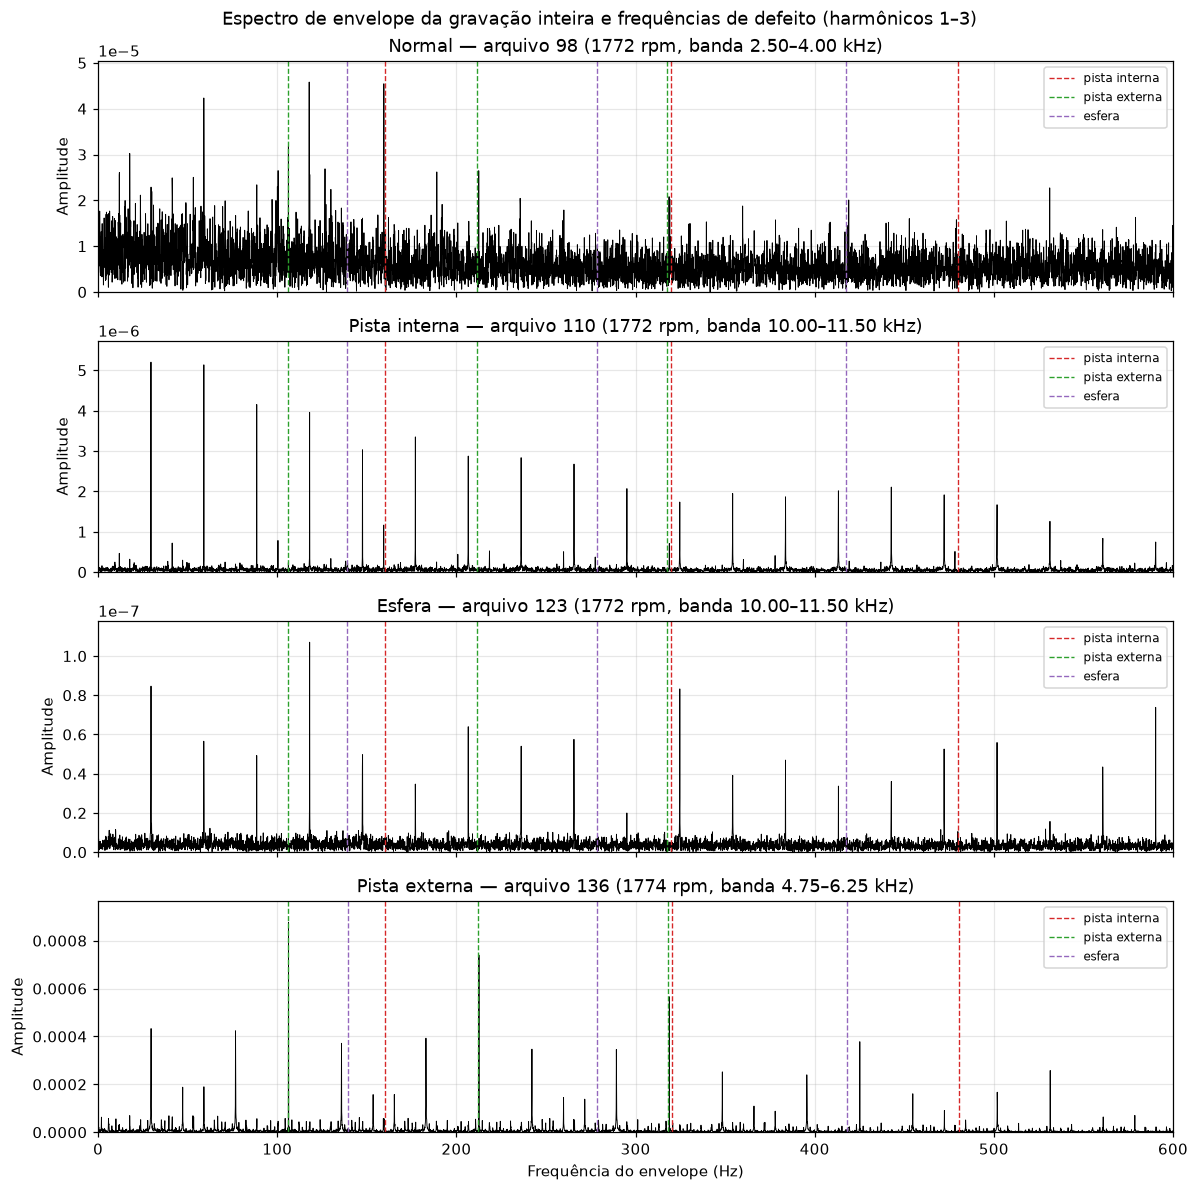

In [7]:
fig, axes = plt.subplots(4, 1, figsize=(11, 11), sharex=True)
colors = {'pista_interna': 'tab:red', 'pista_externa': 'tab:green', 'esfera': 'tab:purple'}
for ax, label in zip(axes, CLASSES):
    row = example_ids[example_ids.classe == label].iloc[0]
    x = signals[row.file_id]
    band, _ = select_band(x)
    env = squared_envelope(x, band)
    freqs = np.fft.rfftfreq(len(env), 1 / FS)
    spectrum = np.abs(np.fft.rfft(env - env.mean())) / len(env)
    ax.plot(freqs, spectrum, lw=0.6, color='k')
    shaft_hz = row.rpm / 60
    for name, order in DEFECT_ORDERS.items():
        for k in (1, 2, 3):
            ax.axvline(k * order * shaft_hz, color=colors[name], ls='--', lw=0.9,
                       label=name.replace('_', ' ') if k == 1 else None)
    ax.set(title=f'{label} — arquivo {row.file_id} ({row.rpm:.0f} rpm, banda {band[0]/1000:.2f}–{band[1]/1000:.2f} kHz)',
           ylabel='Amplitude', ylim=(0, spectrum[(freqs > 5) & (freqs < 600)].max() * 1.1))
    ax.legend(loc='upper right', fontsize=8)
axes[-1].set(xlim=(0, 600), xlabel='Frequência do envelope (Hz)')
fig.suptitle('Espectro de envelope da gravação inteira e frequências de defeito (harmônicos 1–3)')
fig.tight_layout()
fig.savefig(OUT / 'espectro_envelope.png', dpi=150)
plt.show()

A curtose e a curtose do envelope separam bem o normal das falhas: os impactos tornam o sinal mais impulsivo. Os
indicadores de envelope separam em parte os tipos de defeito, mas se sobrepõem em janelas curtas. O `log_rms` muda muito
entre classes **e também entre cargas e diâmetros** — é por isso que ele foi retirado do conjunto principal.

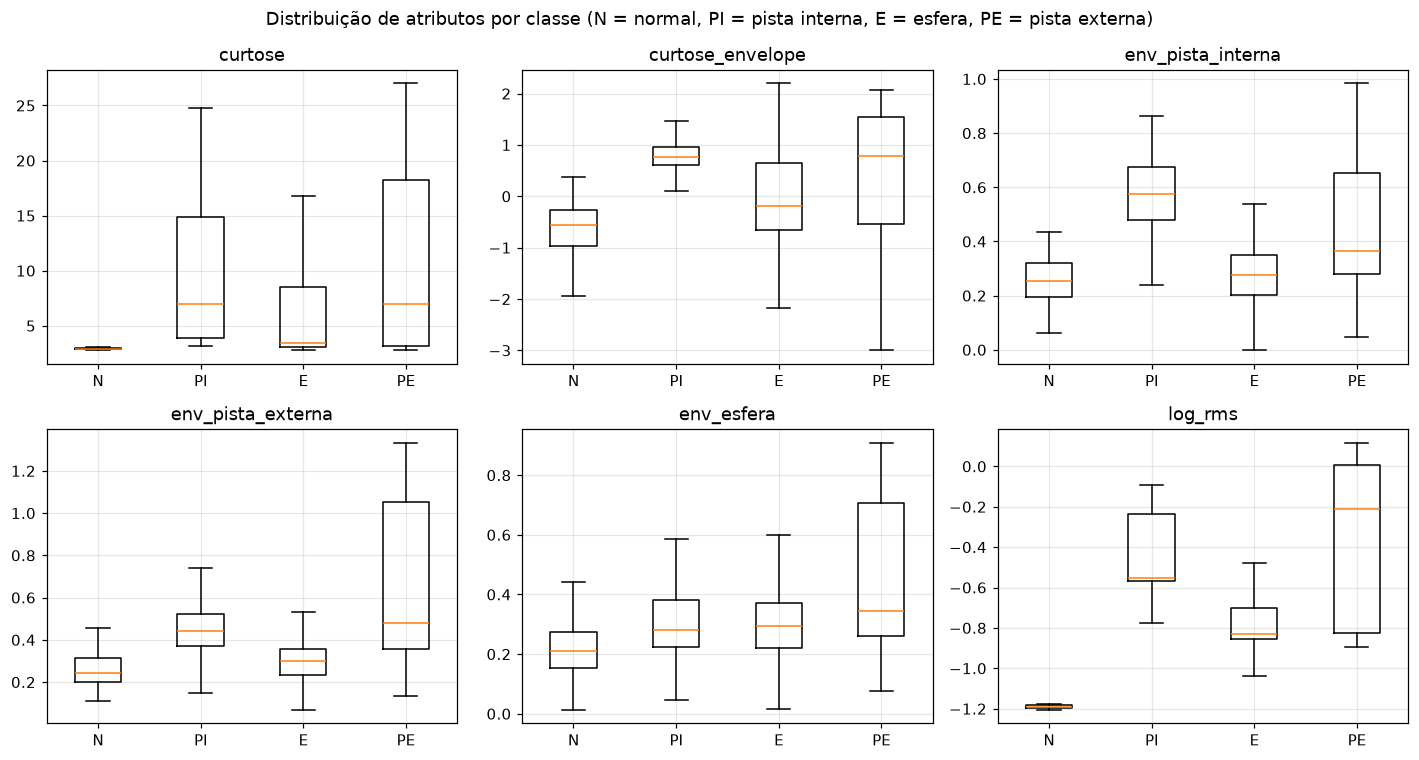

In [8]:
show = ['curtose', 'curtose_envelope', 'env_pista_interna', 'env_pista_externa', 'env_esfera', 'log_rms']
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, feat in zip(axes.ravel(), show):
    ax.boxplot([frame.loc[frame.classe == c, feat] for c in CLASSES], showfliers=False)
    ax.set_xticks(range(1, len(CLASSES) + 1), [SHORT[c] for c in CLASSES])
    ax.set_title(feat)
fig.suptitle('Distribuição de atributos por classe (N = normal, PI = pista interna, E = esfera, PE = pista externa)')
fig.tight_layout()
fig.savefig(OUT / 'atributos_por_classe.png', dpi=150)
plt.show()

## 5. Como separar treino e teste

Nas aulas, a divisão é feita com `train_test_split(X, y, stratify=y, test_size=0.3)`: as linhas da tabela são
sorteadas. Aqui isso seria um erro. Cada gravação vira dezenas de janelas quase idênticas (mesmo rolamento, mesma
carga, mesmo sensor). O sorteio coloca janelas "irmãs" no treino e no teste, e o modelo acerta porque **reconhece a
gravação**, não o defeito. É o **vazamento de dados** (*data leakage*).

O teste abaixo compara as duas formas de separar, com o mesmo modelo e os mesmos atributos:

- **Sorteio de janelas:** `train_test_split`, como nas aulas;
- **Por gravação:** todas as gravações de 0 HP vão para o teste; o modelo nunca viu nenhuma janela delas.

In [9]:
def separar_por_grupo(dados, coluna, valores_teste):
    """Treino/teste por grupo (carga ou diâmetro): cada gravação fica inteira de um lado só."""
    teste = dados[dados[coluna].isin(valores_teste)]
    treino = dados[~dados[coluna].isin(valores_teste)]
    assert set(treino.file_id).isdisjoint(teste.file_id), 'gravação no treino e no teste'
    return treino, teste


X, y = frame[FEATURE_SETS[MAIN_SET]], frame.classe
modelo = RandomForestClassifier(random_state=SEED)

# (a) sorteio de janelas, como nas aulas
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3, random_state=SEED)
acc_sorteio = accuracy_score(y_test, modelo.fit(X_train, y_train).predict(X_test))
repetidas = set(frame.loc[X_train.index, 'file_id']) & set(frame.loc[X_test.index, 'file_id'])

# (b) por gravação: a carga de 0 HP inteira fica no teste
treino, teste = separar_por_grupo(frame, 'carga_hp', [0])
acc_gravacao = accuracy_score(teste.classe, modelo.fit(treino[X.columns], treino.classe).predict(teste[X.columns]))

print(f'Gravações com janelas no treino E no teste, no sorteio: {len(repetidas)} de {frame.file_id.nunique()}')
pd.DataFrame({'Separação': ['(a) sorteio de janelas — train_test_split', '(b) por gravação — teste = 0 HP'],
              'Acurácia no teste': [acc_sorteio, acc_gravacao]}).round(3)

Gravações com janelas no treino E no teste, no sorteio: 40 de 40


,Separação,Acurácia no teste
0,(a) sorteio de janelas — train_test_split,0.993
1,(b) por gravação — teste = 0 HP,0.855


No sorteio, **todas as 40 gravações** têm janelas dos dois lados, e a acurácia fica artificialmente alta (99,3% contra
85,5% quando a carga de teste é realmente nova). Por isso, daqui
em diante **toda divisão é por gravação**, usando o `LeaveOneGroupOut` do scikit-learn: cada grupo vira teste uma vez,
como as dobras do `KFold` da aula de validação cruzada, mas sem quebrar grupos. Usamos dois tipos de grupo:

- **carga** (0, 1, 2 e 3 HP): o modelo funciona numa condição de operação que não viu?
- **diâmetro do defeito** (0,007", 0,014" e 0,021"): o modelo reconhece o *tipo* de defeito num tamanho que não viu?

A figura mostra as 4 dobras por carga, no mesmo estilo do `plot_cv_indices` da aula ML6.

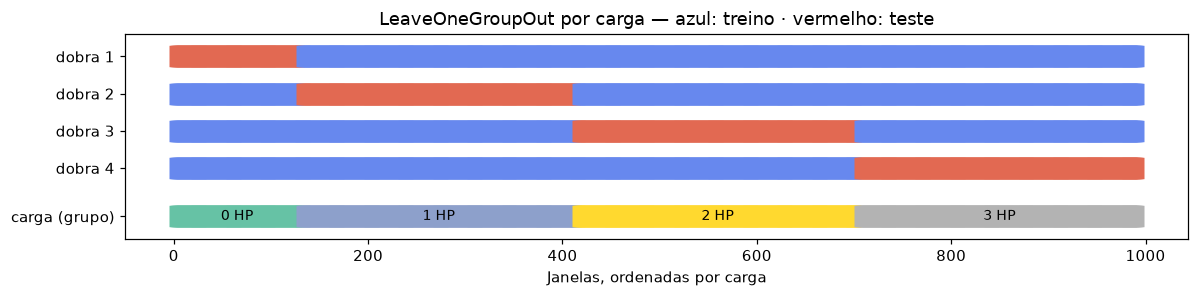

In [10]:
# @title Figura: dobras do LeaveOneGroupOut por carga {display-mode: "form"}
# Você pode pular esta célula: ela só desenha a figura.
ordem = frame.sort_values(['carga_hp', 'file_id', 'janela']).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 2.8))
for dobra, (_, idx_teste) in enumerate(LeaveOneGroupOut().split(ordem, groups=ordem.carga_hp)):
    lado = np.zeros(len(ordem))
    lado[idx_teste] = 1
    ax.scatter(range(len(ordem)), [dobra] * len(ordem), c=lado, marker='_', lw=14, cmap='coolwarm', vmin=-0.2, vmax=1.2)
ax.scatter(range(len(ordem)), [4.3] * len(ordem), c=ordem.carga_hp, marker='_', lw=14, cmap='Set2')
for carga, idx in ordem.groupby('carga_hp').groups.items():
    ax.text(np.mean(idx), 4.3, f'{carga} HP', ha='center', va='center', fontsize=9)
ax.set_yticks([0, 1, 2, 3, 4.3], [f'dobra {d + 1}' for d in range(4)] + ['carga (grupo)'])
ax.set(xlabel='Janelas, ordenadas por carga', ylim=(4.9, -0.6),
       title='LeaveOneGroupOut por carga — azul: treino · vermelho: teste')
ax.grid(False)
fig.tight_layout()
fig.savefig(OUT / 'dobras_por_carga.png', dpi=150)
plt.show()

## 6. Detecção de anomalias

**Pergunta:** um modelo que só conhece a máquina saudável consegue alarmar quando surge um defeito?

Os detectores aprendem **somente com janelas normais**: no início da operação de uma máquina só existem dados dela
saudável. Cada detector devolve um **escore** (maior = mais anômalo) e alarma quando o escore passa de um **limiar**.
Todos usam os 21 atributos do conjunto B.

| Detector | Ideia | Referências |
|---|---|---|
| **Curtose do envelope** | Indicador de saúde clássico, sem aprendizado: impactos deixam o sinal "pontudo" | Antoni (2006); Antoni & Randall (2006) |
| **Mahalanobis** | Distância ao centro da nuvem normal, em "desvios-padrão" que levam em conta as correlações; covariância de Ledoit-Wolf, estável com poucas janelas | De Maesschalck et al. (2000); Ledoit & Wolf (2004) |
| **Isolation Forest** | Pontos anômalos são isolados com poucos cortes aleatórios (citado na aula de *Clustering* como método de detecção de anomalias) | Liu et al. (2008, 2012); Wang et al. (2022) |

In [11]:
DETECT_FEATURES = FEATURE_SETS[MAIN_SET]
DETECTORS = ['Curtose do envelope (indicador)', 'Mahalanobis', 'Isolation Forest']
LOADS = [0, 1, 2, 3]
QUANTILE = 0.99   # limiar = percentil 99 dos escores normais de validação


def escore_anomalia(nome, X_fit, X):
    """Ajusta o detector só com as janelas normais X_fit e devolve o escore de X (maior = mais anômalo)."""
    if nome == 'Curtose do envelope (indicador)':   # indicador clássico: não aprende nada
        return X[:, DETECT_FEATURES.index('curtose_envelope')]
    if nome == 'Mahalanobis':                         # distância ao centro da nuvem normal
        scaler = StandardScaler().fit(X_fit)
        return LedoitWolf().fit(scaler.transform(X_fit)).mahalanobis(scaler.transform(X))
    if nome == 'Isolation Forest':                    # quantos cortes aleatórios isolam a janela
        modelo = make_pipeline(StandardScaler(), IsolationForest(n_estimators=300, random_state=SEED)).fit(X_fit)
        return -modelo.score_samples(X)
    raise ValueError(f'detector desconhecido: {nome}')

### 6.1 Treino, validação e teste (referência normal em cada carga)

Mesma lógica da aula de validação cruzada (ML6): **treino** para ajustar, **validação** para escolher o limiar e
**teste** só no final. Cada gravação normal é dividida em três trechos seguidos no tempo:

| Trecho | Papel |
|---|---|
| 1º terço de cada gravação normal | **treino** do detector |
| 2º terço de cada gravação normal | **validação**: o limiar é o percentil 99 dos escores |
| 3º terço de cada gravação normal + todas as gravações com falha | **teste** |

É o cenário de uma planta que grava a máquina saudável em cada condição de operação antes de monitorá-la. Ele é
**otimista quanto ao FPR**: o normal de teste vem da mesma gravação do treino, só que mais adiante no tempo.

In [12]:
normal = frame[frame.classe == 'Normal'].copy()
normal['terco'] = normal.groupby('file_id').janela.transform(
    lambda s: np.minimum(3 * s.rank(method='first').sub(1) // len(s), 2).astype(int))
fit_part, calib_part, normal_test = (normal[normal.terco == k] for k in (0, 1, 2))
test_b = pd.concat([normal_test, frame[frame.classe != 'Normal']])
assert (fit_part.classe == 'Normal').all() and (calib_part.classe == 'Normal').all()
assert set(fit_part.index).isdisjoint(test_b.index) and set(calib_part.index).isdisjoint(test_b.index)
y_b = (test_b.classe != 'Normal').to_numpy()

X_fit = fit_part[DETECT_FEATURES].to_numpy()
baseline_rows, baseline_scores = [], {}
for name in DETECTORS:
    threshold = np.quantile(escore_anomalia(name, X_fit, calib_part[DETECT_FEATURES].to_numpy()), QUANTILE)
    scores = escore_anomalia(name, X_fit, test_b[DETECT_FEATURES].to_numpy())
    alarm = scores > threshold
    baseline_scores[name] = (scores, threshold)
    baseline_rows.append({'detector': name, 'TPR': alarm[y_b].mean(), 'FPR': alarm[~y_b].mean(),
                          'ROC-AUC': roc_auc_score(y_b, scores)})
baseline_table = pd.DataFrame(baseline_rows).set_index('detector')
baseline_table.to_csv(OUT / 'deteccao_referencia_por_carga.csv')
print(f'Janelas normais: treino {len(fit_part)}, validação {len(calib_part)}, teste {len(normal_test)}')
baseline_table.round(4)

Janelas normais: treino 35, validação 35, teste 31


,TPR,FPR,ROC-AUC
detector,,,
Curtose do envelope (indicador),0.7002,0.0323,0.8098
Mahalanobis,1.0000,0.0000,1.0000
Isolation Forest,0.7260,0.0323,0.9732


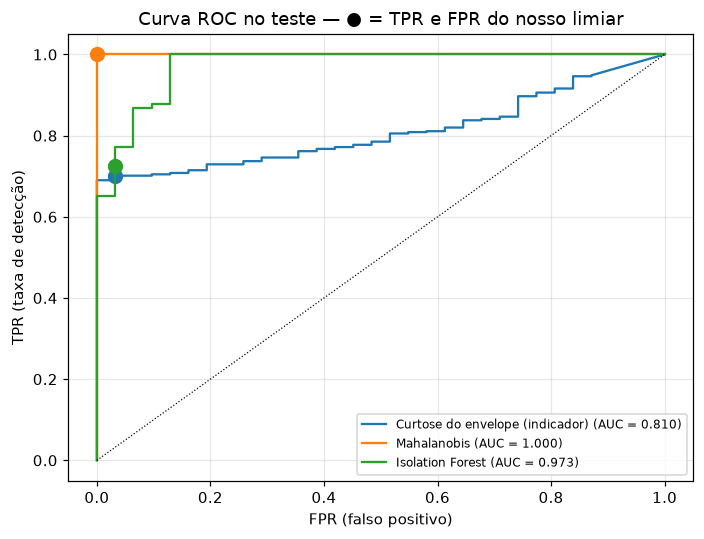

In [13]:
# @title Figura: curvas ROC e o ponto do nosso limiar {display-mode: "form"}
# Você pode pular esta célula: ela só desenha a figura.
fig, ax = plt.subplots(figsize=(6.5, 5))
for name, (scores, threshold) in baseline_scores.items():
    fpr, tpr, _ = roc_curve(y_b, scores)
    line, = ax.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_b, scores):.3f})')
    alarm = scores > threshold
    ax.plot(alarm[~y_b].mean(), alarm[y_b].mean(), 'o', color=line.get_color(), ms=9)
ax.plot([0, 1], [0, 1], 'k:', lw=0.8)
ax.set(xlabel='FPR (falso positivo)', ylabel='TPR (taxa de detecção)',
       title='Curva ROC no teste — ● = TPR e FPR do nosso limiar')
ax.legend(fontsize=8, loc='lower right')
fig.tight_layout()
fig.savefig(OUT / 'deteccao_roc.png', dpi=150)
plt.show()

**Leitura.** A curva ROC responde à pergunta da aula `IMT_ROC`: *qual o TPR e o FPR para o limiar que escolhemos?*

- **Mahalanobis** detecta **100% das falhas sem nenhum falso alarme**: o ponto fica no canto superior esquerdo.
- **Isolation Forest** e **curtose do envelope** ordenam bem as janelas (AUC de 0,97 e 0,81), mas o limiar no percentil
  99 foi feito para errar pouco no normal (FPR de 3%, 1 de 31 janelas) e deixa passar cerca de 30% das falhas.

Ou seja: **com uma referência normal da mesma carga, a detecção funciona.** A próxima seção tira essa ajuda.

### 6.2 E se a carga for nova?

Agora o caso difícil: o detector nunca viu a máquina saudável **naquela carga**. São 4 dobras, deixando uma carga de
fora (`LeaveOneGroupOut`, seção 5): o detector treina com os normais das outras três cargas e é testado em todas as
gravações da carga deixada de fora.

**Limiar por validação cruzada.** Dentro do treino, cada carga normal faz o papel de **validação** uma vez: ela é
pontuada por um detector treinado só com as outras. O limiar é o percentil 99 desses escores, então ele já simula a
mudança de carga sem olhar o teste.

In [14]:
det_windows, det_thresholds = [], []
for test_load in LOADS:
    train_loads = [l for l in LOADS if l != test_load]
    normal_train = frame[(frame.classe == 'Normal') & frame.carga_hp.isin(train_loads)]
    test = frame[frame.carga_hp == test_load]
    for name in DETECTORS:
        # validação cruzada dentro do treino: cada carga normal é pontuada por um detector que não a viu
        held_out_scores = [escore_anomalia(name,
                                           normal_train[normal_train.carga_hp != held][DETECT_FEATURES].to_numpy(),
                                           normal_train[normal_train.carga_hp == held][DETECT_FEATURES].to_numpy())
                           for held in train_loads]
        threshold = float(np.quantile(np.concatenate(held_out_scores), QUANTILE))
        scores = escore_anomalia(name, normal_train[DETECT_FEATURES].to_numpy(), test[DETECT_FEATURES].to_numpy())
        det_thresholds.append(dict(detector=name, carga_teste=test_load, limiar=threshold))
        det_windows.append(pd.DataFrame(dict(detector=name, carga_teste=test_load, file_id=test.file_id.values,
                                             classe=test.classe.values, escore=scores, alarme=scores > threshold)))
det_windows = pd.concat(det_windows, ignore_index=True)
det_windows['falha'] = det_windows.classe != 'Normal'

rows = []
for name, g in det_windows.groupby('detector', sort=False):
    rows.append({'detector': name, 'TPR': g.alarme[g.falha].mean(), 'FPR': g.alarme[~g.falha].mean(),
                 # escores só são comparáveis dentro da mesma dobra: AUC = média das dobras
                 'ROC-AUC (média)': np.mean([roc_auc_score(f.falha, f.escore) for _, f in g.groupby('carga_teste')])})
fpr_by_load = det_windows[~det_windows.falha].pivot_table(index='detector', columns='carga_teste',
                                                          values='alarme', aggfunc='mean', sort=False)
fpr_by_load.columns = [f'FPR {c} HP' for c in fpr_by_load.columns]
detection_table = pd.DataFrame(rows).set_index('detector').join(fpr_by_load)
detection_table.to_csv(OUT / 'deteccao_resumo.csv')
pd.DataFrame(det_thresholds).to_csv(OUT / 'deteccao_limiares.csv', index=False)
detection_table.round(4)

,TPR,FPR,ROC-AUC (média),FPR 0 HP,FPR 1 HP,FPR 2 HP,FPR 3 HP
detector,,,,,,,
Curtose do envelope (indicador),0.6790,0.0297,0.8292,0.0000,0.069,0.0345,0.0
Mahalanobis,0.7282,0.1386,1.0000,1.0000,0.000,0.0000,0.0
Isolation Forest,0.8076,0.0891,0.9754,0.6429,0.000,0.0000,0.0


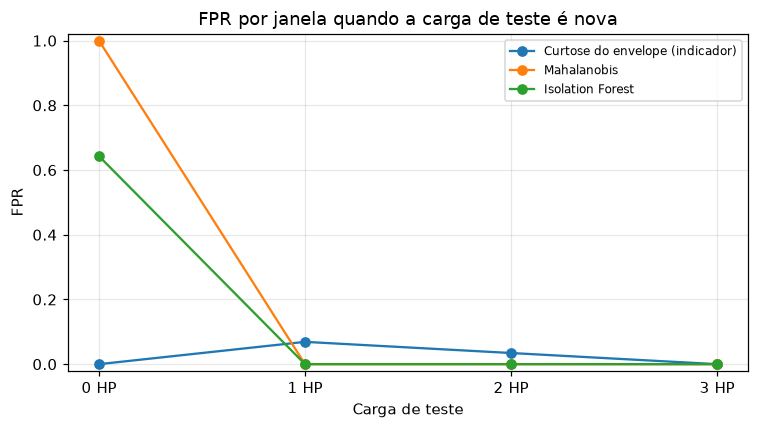

In [15]:
# @title Figura: falso alarme em cada carga nova {display-mode: "form"}
# Você pode pular esta célula: ela só desenha a figura.
fig, ax = plt.subplots(figsize=(7, 4))
fpr_by_load.T.plot(ax=ax, marker='o')
ax.set(title='FPR por janela quando a carga de teste é nova', xlabel='Carga de teste', ylabel='FPR',
       ylim=(-0.02, 1.02))
ax.set_xticks(range(4), [f'{c} HP' for c in LOADS])
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'deteccao_fpr_por_carga.png', dpi=150)
plt.show()

**Leitura.**

- **Os escores continuam ordenando muito bem.** A ROC-AUC média é 1,000 para Mahalanobis e 0,975 para o Isolation
  Forest: em cada carga, toda janela com falha tem escore de Mahalanobis maior que toda janela normal.
- **O problema é o limiar.** Quando a carga de teste é **0 HP**, a única gravação normal disponível (arquivo 97) recebe
  alarme em 64% (Isolation Forest) a 100% das janelas (Mahalanobis): o normal a 0 HP difere dos normais de 1–3 HP.
  Quando 0 HP está no treino, o mesmo arquivo eleva o limiar, e parte das falhas fica abaixo dele (TPR de 73% a 81%).
- **O indicador simples tem o menor FPR** (3%) e o menor TPR (68%): falhas menos impulsivas não se destacam.

**Conclusão da detecção:** a 6.1 mostra que a detecção funciona; o que falha aqui é **transferir o limiar para uma carga
nova**. Com só quatro gravações normais, uma por carga, não há dados para calibrar um limiar que sirva em todas.

## 7. Diagnóstico do tipo de falha

**Pergunta:** além de alarmar, dá para dizer *qual* é a falha — pista interna, esfera ou pista externa?

Os classificadores aprendem com janelas rotuladas das quatro classes.

| Modelo | Ideia | Hiperparâmetros testados | Referências |
|---|---|---|---|
| **Random Forest** | Muitas árvores de decisão com aleatoriedade; voto da maioria | folha mínima ∈ {1, 5, 10}; 300 árvores; pesos balanceados | Breiman (2001); Yang et al. (2008) |
| **SVM RBF** | Fronteira de margem máxima com kernel gaussiano | C ∈ {0,1; 1; 10; 100}; padronização no treino; pesos balanceados | Cortes & Vapnik (1995); Widodo & Yang (2007) |
| **Regra de envelope** | Física: vence o maior indicador BPFI/BPFO/BSF da gravação inteira | Sem treino de fronteira; limiar normal = maior valor visto em normais de treino | Randall & Antoni (2011); Smith & Randall (2015) |

**Seleção de hiperparâmetros: o mesmo laço da aula de seleção de modelos (ML7).** Uma lista de modelos
(`base_estimators`), uma lista de grades (`param_grids`) e um `GridSearchCV` para cada modelo, seguido de
`classification_report`. Há só duas diferenças, as duas explicadas na seção 5:

- `cv=LeaveOneGroupOut()` no lugar de `cv=5`: a validação interna também separa por carga (ou por diâmetro);
- `scoring='f1_macro'` no lugar de `accuracy`: o normal tem bem menos janelas que as falhas, e a macro-F1 dá o mesmo
  peso a cada classe.

Esse laço roda **dentro** de cada dobra externa: cada carga (ou diâmetro) vira teste uma vez, e o teste só é usado
depois que o `GridSearchCV` escolheu os hiperparâmetros.

In [16]:
base_estimators = [RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=SEED, n_jobs=-1),
                   make_pipeline(StandardScaler(), SVC(kernel='rbf', gamma='scale', class_weight='balanced'))]
param_grids = [{'min_samples_leaf': [1, 5, 10]},
               {'svc__C': [0.1, 1, 10, 100]}]
MODEL_NAMES = ['Random Forest', 'SVM RBF']


def diagnosticar(dados, grupo, conjuntos):
    """Para cada grupo deixado de fora (carga ou diâmetro), roda o laço da aula ML7 em cada conjunto de atributos."""
    predictions, choices = [], []
    for held in sorted(dados[grupo].unique()):                  # cada grupo vira teste uma vez
        train, test = separar_por_grupo(dados, grupo, [held])
        for set_name, cols in conjuntos.items():
            for i in range(len(base_estimators)):
                clf = GridSearchCV(base_estimators[i], param_grids[i], cv=LeaveOneGroupOut(), scoring='f1_macro')
                clf.fit(train[cols], train.classe, groups=train[grupo])
                y_pred = clf.predict(test[cols])
                predictions.append(pd.DataFrame(dict(conjunto=set_name, modelo=MODEL_NAMES[i], dobra=held,
                                                     file_id=test.file_id.values, classe=test.classe.values,
                                                     predicao=y_pred)))
                choices.append(dict(conjunto=set_name, modelo=MODEL_NAMES[i], dobra=held,
                                    parametro=str(clf.best_params_), macro_f1_validacao_interna=clf.best_score_))
    return pd.concat(predictions, ignore_index=True), pd.DataFrame(choices)


def summarize(preds, labels):
    """Resumo por conjunto e modelo, somando as dobras (cada janela aparece uma vez no teste)."""
    rows = []
    for (set_name, model), g in preds.groupby(['conjunto', 'modelo'], sort=False):
        per_fold = [f1_score(f.classe, f.predicao, labels=labels, average='macro', zero_division=0)
                    for _, f in g.groupby('dobra')]
        rec = recall_score(g.classe, g.predicao, labels=labels, average=None, zero_division=0)
        votes = g.groupby('file_id').agg(classe=('classe', 'first'),
                                         voto=('predicao', lambda s: s.value_counts().index[0]))
        row = {'conjunto': set_name, 'modelo': model,
               'acurácia': accuracy_score(g.classe, g.predicao),
               'macro-F1 (média dobras)': np.mean(per_fold), 'macro-F1 (desvio)': np.std(per_fold),
               'macro-F1 (pior dobra)': np.min(per_fold),
               'acurácia por gravação (voto)': (votes.classe == votes.voto).mean()}
        row.update({f'recall {c}': r for c, r in zip(labels, rec)})
        rows.append(row)
    return pd.DataFrame(rows)


def f1_por_dobra(preds, labels):
    """Macro-F1 de cada dobra (linhas: conjunto e modelo; colunas: grupo deixado de fora)."""
    f1 = pd.Series({key: f1_score(g.classe, g.predicao, labels=labels, average='macro', zero_division=0)
                    for key, g in preds.groupby(['conjunto', 'modelo', 'dobra'], sort=False)})
    return f1.rename_axis(['conjunto', 'modelo', 'dobra']).unstack('dobra')

### 7.1 Carga nova (4 classes)

4 dobras, deixando uma carga de fora. Cada gravação aparece no teste exatamente uma vez.

In [17]:
lolo_preds, lolo_choices = diagnosticar(frame, 'carga_hp', {MAIN_SET: FEATURE_SETS[MAIN_SET]})
lolo_summary = summarize(lolo_preds, CLASSES)
lolo_preds.to_csv(OUT / 'predicoes_carga.csv', index=False)
lolo_choices.to_csv(OUT / 'selecao_hiperparametros_carga.csv', index=False)
lolo_summary.to_csv(OUT / 'diagnostico_carga.csv', index=False)

for model, g in lolo_preds.groupby('modelo', sort=False):
    print(f'=== {model} — 4 dobras somadas ===')
    print(classification_report(g.classe, g.predicao, labels=CLASSES, zero_division=0))

f1_por_carga = f1_por_dobra(lolo_preds, CLASSES)
f1_por_carga.columns = [f'macro-F1 teste {c} HP' for c in f1_por_carga.columns]
f1_por_carga.to_csv(OUT / 'diagnostico_por_carga.csv')
f1_por_carga.round(3)

=== Random Forest — 4 dobras somadas ===
               precision    recall  f1-score   support

       Normal       0.99      1.00      1.00       101
Pista interna       1.00      0.95      0.97       286
       Esfera       0.92      0.99      0.95       304
Pista externa       0.99      0.95      0.97       304

     accuracy                           0.97       995
    macro avg       0.97      0.97      0.97       995
 weighted avg       0.97      0.97      0.97       995

=== SVM RBF — 4 dobras somadas ===
               precision    recall  f1-score   support

       Normal       1.00      0.95      0.97       101
Pista interna       0.99      0.97      0.98       286
       Esfera       0.87      0.92      0.89       304
Pista externa       0.93      0.90      0.92       304

     accuracy                           0.93       995
    macro avg       0.95      0.94      0.94       995
 weighted avg       0.93      0.93      0.93       995



macro-F1 teste 0 HP  \
conjunto                    modelo                               
B: adimensionais + envelope Random Forest                0.827   
                            SVM RBF                      0.873   

                                           macro-F1 teste 1 HP  \
conjunto                    modelo                               
B: adimensionais + envelope Random Forest                0.997   
                            SVM RBF                      0.933   

                                           macro-F1 teste 2 HP  \
conjunto                    modelo                               
B: adimensionais + envelope Random Forest                0.991   
                            SVM RBF                      0.923   

                                           macro-F1 teste 3 HP  
conjunto                    modelo                              
B: adimensionais + envelope Random Forest                0.994  
                            SVM RBF                      0.991

Com carga nova, os modelos acertam bem: macro-F1 médio de 0,95 (Random Forest) e 0,93 (SVM). Mas a tabela por carga
mostra que **não é igual em todas as cargas**: com 0 HP no teste, a macro-F1 cai para 0,83 (RF) e 0,87 (SVM). É a carga
com gravações mais curtas e com o normal atípico. Testar só numa carga "boa" esconderia esse pior caso.

### 7.2 Diâmetro novo (3 tipos de falha)

Treino com dois diâmetros (todas as cargas) e teste no terceiro. A pergunta é: **o modelo reconhece o *tipo* de defeito
numa severidade que nunca viu?** É o teste mais próximo de um defeito novo em campo. As gravações normais ficam de fora,
porque não têm diâmetro. Aqui comparamos também o conjunto C (só envelope).

In [18]:
FAULT_CLASSES = CLASSES[1:]
faults = frame[frame.classe != 'Normal']
lodo_preds, lodo_choices = diagnosticar(faults, 'diametro_pol', FEATURE_SETS)
lodo_summary = summarize(lodo_preds, FAULT_CLASSES)
lodo_by_diameter = f1_por_dobra(lodo_preds, FAULT_CLASSES)
lodo_by_diameter.columns = [f'macro-F1 teste {d}"' for d in lodo_by_diameter.columns]
lodo_preds.to_csv(OUT / 'predicoes_diametro.csv', index=False)
lodo_choices.to_csv(OUT / 'selecao_hiperparametros_diametro.csv', index=False)
lodo_summary.to_csv(OUT / 'diagnostico_diametro.csv', index=False)
lodo_by_diameter.to_csv(OUT / 'diagnostico_por_diametro.csv')
lodo_by_diameter.round(3)

macro-F1 teste 0.007"  \
conjunto                    modelo                                 
B: adimensionais + envelope Random Forest                  0.167   
                            SVM RBF                        0.029   
C: somente envelope         Random Forest                  0.332   
                            SVM RBF                        0.729   

                                           macro-F1 teste 0.014"  \
conjunto                    modelo                                 
B: adimensionais + envelope Random Forest                  0.155   
                            SVM RBF                        0.171   
C: somente envelope         Random Forest                  0.437   
                            SVM RBF                        0.481   

                                           macro-F1 teste 0.021"  
conjunto                    modelo                                
B: adimensionais + envelope Random Forest                  0.033  
                            SVM RBF                        0.019  
C: somente envelope         Random Forest                  0.466  
                            SVM RBF                        0.465

**O resultado se inverte.** Com o conjunto B, Random Forest e SVM ficam **abaixo do acaso** (macro-F1 de 0,07 a 0,12,
contra 0,33 de um chute). As matrizes da seção 7.4 mostram por quê: os modelos atribuem praticamente todas as
gravações do diâmetro novo a uma única classe. Eles aprenderam a "assinatura" de cada gravação ou rolamento, e não o que
caracteriza um defeito de pista interna, esfera ou pista externa. Só o conjunto C, com atributos físicos, mantém algum
poder de generalização (macro-F1 de 0,41 a 0,56).

### 7.3 Regra de envelope por gravação

A regra física diagnostica cada gravação pelo maior indicador de envelope calculado sobre o **sinal inteiro** (10 s). Ela
não aprende fronteiras: só precisa da geometria do rolamento e da rotação. A comparação justa com o ML é por gravação,
usando o voto majoritário das janelas.

In [19]:
ENV_COLUMNS = {'Pista interna': 'env_pista_interna', 'Esfera': 'env_esfera', 'Pista externa': 'env_pista_externa'}


def envelope_rule(train_recs, test_recs):
    """Diagnóstico clássico por gravação: vence o maior indicador de envelope.
    Com dados normais no treino, abaixo do maior valor visto em gravações normais → Normal."""
    values = test_recs[list(ENV_COLUMNS.values())].to_numpy()
    labels = np.array(list(ENV_COLUMNS))[values.argmax(axis=1)]
    if train_recs is None:
        return labels
    normal_values = train_recs.loc[train_recs.classe == 'Normal', list(ENV_COLUMNS.values())]
    return np.where(values.max(axis=1) > normal_values.to_numpy().max(), labels, 'Normal')


def votes(preds):
    """Uma decisão por gravação: a classe mais votada entre as janelas."""
    return (preds.groupby(['conjunto', 'modelo', 'file_id'], sort=False)
            .agg(classe=('classe', 'first'), predicao=('predicao', lambda s: s.value_counts().index[0]))
            .reset_index())


rule_load = pd.concat([recording_env[recording_env.carga_hp == load].assign(
    predicao=lambda t, load=load: envelope_rule(recording_env[recording_env.carga_hp != load], t))
    for load in LOADS])
rule_diam = recording_env[recording_env.classe != 'Normal'].assign(predicao=lambda t: envelope_rule(None, t))

comparison = []
for protocol, rule_df, ml_votes, labels in [
        ('carga não vista', rule_load, votes(lolo_preds), CLASSES),
        ('diâmetro não visto', rule_diam, votes(lodo_preds), FAULT_CLASSES)]:
    comparison.append({'protocolo': protocol, 'método': 'Regra de envelope (física)', 'conjunto': '—',
                       'acurácia': accuracy_score(rule_df.classe, rule_df.predicao),
                       'macro-F1': f1_score(rule_df.classe, rule_df.predicao, labels=labels, average='macro'),
                       'gravações': len(rule_df)})
    for (set_name, model), g in ml_votes.groupby(['conjunto', 'modelo'], sort=False):
        comparison.append({'protocolo': protocol, 'método': f'{model} (voto das janelas)', 'conjunto': set_name,
                           'acurácia': accuracy_score(g.classe, g.predicao),
                           'macro-F1': f1_score(g.classe, g.predicao, labels=labels, average='macro'),
                           'gravações': len(g)})
recording_comparison = pd.DataFrame(comparison)
recording_comparison.to_csv(OUT / 'comparacao_por_gravacao.csv', index=False)
rule_load.to_csv(OUT / 'regra_envelope_carga.csv', index=False)
rule_diam.to_csv(OUT / 'regra_envelope_diametro.csv', index=False)
recording_comparison.round(3)

,protocolo,método,conjunto,acurácia,macro-F1,gravações
0,carga não vista,Regra de envelope (física),—,0.550,0.482,40
1,carga não vista,Random Forest (voto das janelas),B: adimensionais + envelope,0.925,0.939,40
2,carga não vista,SVM RBF (voto das janelas),B: adimensionais + envelope,0.900,0.918,40
3,diâmetro não visto,Regra de envelope (física),—,0.694,0.681,36
4,diâmetro não visto,Random Forest (voto das janelas),B: adimensionais + envelope,0.222,0.184,36
5,diâmetro não visto,SVM RBF (voto das janelas),B: adimensionais + envelope,0.111,0.083,36
6,diâmetro não visto,Random Forest (voto das janelas),C: somente envelope,0.556,0.469,36
7,diâmetro não visto,SVM RBF (voto das janelas),C: somente envelope,0.639,0.618,36


**Diâmetro não visto (por gravação):** a regra de envelope acerta **69%** das 36 gravações, contra 11% a 22% do ML com
o conjunto B e 56% a 64% do ML só com envelope. Ela acerta quase todas as pistas interna e externa de 0,007" e
0,021"; erra principalmente as esferas e o diâmetro de 0,014".

**Carga não vista (por gravação):** o ML vence com folga (90% a 92,5% contra 55%). A regra perde porque não reconhece
nenhuma esfera e porque o normal de 0 HP (arquivo 97) tem indicador de pista interna alto, o que eleva o limiar de
normalidade.

### 7.4 Matrizes de confusão completas

Todas as classes do recorte, somando as dobras (cada janela ou gravação aparece uma única vez).

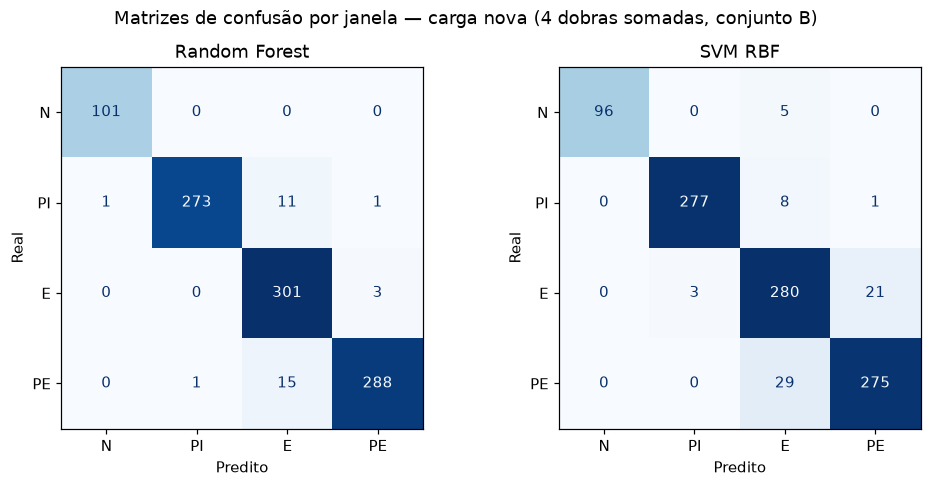

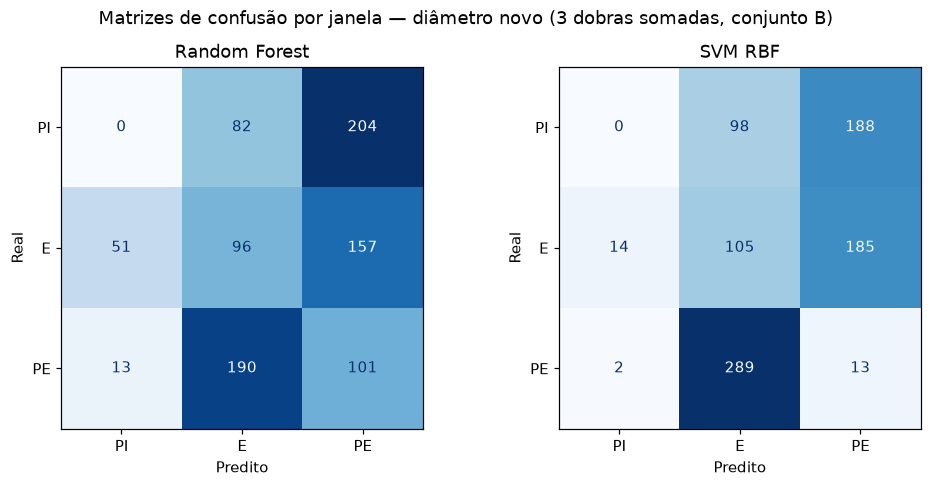

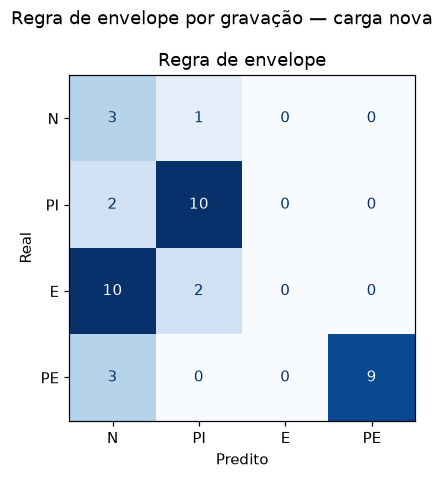

In [20]:
def matrizes(fontes, labels, nome, titulo):
    """Matriz de confusão (ConfusionMatrixDisplay) de cada fonte; salva também o CSV de cada uma."""
    fig, axes = plt.subplots(1, len(fontes), figsize=(4.6 * len(fontes), 4.4), squeeze=False)
    for ax, (slug, model, g) in zip(axes[0], fontes):
        cm = confusion_matrix(g.classe, g.predicao, labels=labels)
        pd.DataFrame(cm, index=labels, columns=labels).to_csv(OUT / f'matriz_{nome}_{slug}.csv')
        ConfusionMatrixDisplay(cm, display_labels=[SHORT[c] for c in labels]).plot(ax=ax, cmap='Blues', colorbar=False)
        ax.set(title=model, xlabel='Predito', ylabel='Real')
        ax.grid(False)
    fig.suptitle(titulo)
    fig.tight_layout()
    fig.savefig(OUT / f'matrizes_{nome}.png', dpi=150)
    plt.show()


def fontes_ml(preds):
    return [(slug, model, preds[(preds.conjunto == MAIN_SET) & (preds.modelo == model)])
            for slug, model in [('rf', 'Random Forest'), ('svm', 'SVM RBF')]]


matrizes(fontes_ml(lolo_preds), CLASSES, 'carga',
         'Matrizes de confusão por janela — carga nova (4 dobras somadas, conjunto B)')
matrizes(fontes_ml(lodo_preds), FAULT_CLASSES, 'diametro',
         'Matrizes de confusão por janela — diâmetro novo (3 dobras somadas, conjunto B)')
matrizes([('regra_envelope', 'Regra de envelope', rule_load)], CLASSES, 'regra',
         'Regra de envelope por gravação — carga nova')

Principal achado do trabalho: **o que funciona para uma carga nova não funciona para um defeito de tamanho novo**.
Atributos estatísticos ganham quando o mesmo rolamento aparece com outra carga; atributos físicos são os únicos que
mantêm algum desempenho num diâmetro nunca visto.

## 8. Tabela resumo (formato do enunciado)

Protocolo 1 (carga não vista), conjunto B, métricas por janela somando as 4 dobras — exceto a regra de envelope, avaliada
por gravação. Para os classificadores, TPR e FPR tratam qualquer classe diferente de Normal como alarme. "Tipo de falha
identificada" lista as classes com recall ≥ 0,5. "Acurácia por classe" é o recall de cada classe
(N = normal, PI = pista interna, E = esfera, PE = pista externa).

In [21]:
def recognized(recalls):
    names = [c for c in CLASSES[1:] if recalls[c] >= 0.5]
    return '; '.join(names) if names else 'nenhum'


summary_rows = []
for name, row in detection_table.iterrows():
    summary_rows.append({'Dataset': 'CWRU 48 kHz DE', 'Técnica': f'{name} — detecção, por janela',
                         'Tipo de falha identificada': 'não se aplica',
                         'Taxa de detecção (TPR)': row['TPR'], 'Falso positivo (FPR)': row['FPR'],
                         'Acurácia por classe (recall)': 'não se aplica'})
main = lolo_preds[lolo_preds.conjunto == MAIN_SET]
diagnosis_sources = [(f'{m} — diagnóstico, por janela', g) for m, g in main.groupby('modelo', sort=False)]
diagnosis_sources.append(('Regra de envelope — diagnóstico, por gravação', rule_load))
for technique, g in diagnosis_sources:
    recalls = dict(zip(CLASSES, recall_score(g.classe, g.predicao, labels=CLASSES, average=None, zero_division=0)))
    fault, alarm = g.classe != 'Normal', g.predicao != 'Normal'
    summary_rows.append({'Dataset': 'CWRU 48 kHz DE', 'Técnica': technique,
                         'Tipo de falha identificada': recognized(recalls),
                         'Taxa de detecção (TPR)': alarm[fault].mean(), 'Falso positivo (FPR)': alarm[~fault].mean(),
                         'Acurácia por classe (recall)': '; '.join(f'{SHORT[c]}: {recalls[c]:.2f}' for c in CLASSES)})
summary_table = pd.DataFrame(summary_rows)
summary_table.to_csv(OUT / 'tabela_resumo.csv', index=False)
(OUT / 'tabela_resumo.md').write_text(summary_table.to_markdown(index=False, floatfmt='.4f'), encoding='utf-8')
display(Markdown(summary_table.to_markdown(index=False, floatfmt='.4f')))

| Dataset        | Técnica                                                | Tipo de falha identificada           |   Taxa de detecção (TPR) |   Falso positivo (FPR) | Acurácia por classe (recall)         |
|:---------------|:-------------------------------------------------------|:-------------------------------------|-------------------------:|-----------------------:|:-------------------------------------|
| CWRU 48 kHz DE | Curtose do envelope (indicador) — detecção, por janela | não se aplica                        |                   0.6790 |                 0.0297 | não se aplica                        |
| CWRU 48 kHz DE | Mahalanobis — detecção, por janela                     | não se aplica                        |                   0.7282 |                 0.1386 | não se aplica                        |
| CWRU 48 kHz DE | Isolation Forest — detecção, por janela                | não se aplica                        |                   0.8076 |                 0.0891 | não se aplica                        |
| CWRU 48 kHz DE | Random Forest — diagnóstico, por janela                | Pista interna; Esfera; Pista externa |                   0.9989 |                 0.0000 | N: 1.00; PI: 0.95; E: 0.99; PE: 0.95 |
| CWRU 48 kHz DE | SVM RBF — diagnóstico, por janela                      | Pista interna; Esfera; Pista externa |                   1.0000 |                 0.0495 | N: 0.95; PI: 0.97; E: 0.92; PE: 0.90 |
| CWRU 48 kHz DE | Regra de envelope — diagnóstico, por gravação          | Pista interna; Pista externa         |                   0.5833 |                 0.2500 | N: 0.75; PI: 0.83; E: 0.00; PE: 0.75 |

Os erros dos classificadores se concentram em **0 HP** (gravações mais curtas, com 3 a 14 janelas) e no diâmetro de
**0,014"**, sobretudo confundidos com esfera. O arquivo 174 tem só 3 janelas, porque a gravação da fonte tem 1,3 s.

## 9. Reprodutibilidade

Versões dos pacotes, parâmetros e lista de atributos ficam em `resultados/ambiente.json`. Todas as métricas ficam em
`resultados/metricas.json` e nos CSVs de `resultados/`.

In [22]:
versions = {p: importlib.metadata.version(p) for p in
            ['numpy', 'scipy', 'pandas', 'scikit-learn', 'matplotlib', 'requests']}
environment = dict(python=sys.version, plataforma=platform.platform(), pacotes=versions, seed=SEED,
                   fs=FS, janela=WINDOW, conjunto_principal=MAIN_SET, quantil_limiar=QUANTILE,
                   atributos=GROUPS)
(OUT / 'ambiente.json').write_text(json.dumps(environment, ensure_ascii=False, indent=2), encoding='utf-8')
metrics = dict(deteccao=detection_table.reset_index().to_dict(orient='records'),
               deteccao_referencia_por_carga=baseline_table.reset_index().to_dict(orient='records'),
               comparacao_por_gravacao=recording_comparison.to_dict(orient='records'),
               diagnostico_carga=lolo_summary.to_dict(orient='records'),
               diagnostico_diametro=lodo_summary.to_dict(orient='records'))
(OUT / 'metricas.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2, default=float), encoding='utf-8')
print(json.dumps(versions, indent=1))

{
 "numpy": "2.5.4",
 "scipy": "1.18.1",
 "pandas": "3.1.1",
 "scikit-learn": "1.9.1",
 "matplotlib": "3.11.2",
 "requests": "2.34.2"
}


## 10. Conclusões

1. **Detecção:** os escores separam normal e falha quase perfeitamente (ROC-AUC ≈ 1), mas o limiar não se transfere entre
   cargas com só 4 gravações normais. Com uma referência normal em cada carga, Mahalanobis detecta 100% das falhas sem
   falsos alarmes.
2. **Diagnóstico com carga nova:** Random Forest e SVM acertam 93–97% das janelas e 90–92,5% das gravações.
3. **Diagnóstico com defeito de tamanho novo:** os modelos estatísticos colapsam abaixo do acaso; só os atributos de
   envelope, baseados na física do rolamento, generalizam em parte. A alta acurácia com o CWRU **não** significa que o
   modelo aprendeu o tipo de defeito.
4. **Esfera** é a classe mais difícil para a abordagem física, como relata a literatura.

A discussão completa, as limitações e as referências estão no [relatório técnico](RELATORIO.md).

**Uso de IA:** ferramentas de IA generativa (ChatGPT/Codex e Claude) foram usadas como apoio na escrita e revisão do
código e do texto; os detalhes estão na seção 9 do relatório. Todas as métricas resultam da execução deste notebook em
dados reais.